# 線性回歸（—）

- **核心原理**：最小平方法、梯度下降
- **推薦資料集**：California Housing


## 資料與探索性資料分析

In [2]:
# Load data
from ml_dl_llm.data import load_california_housing

X_train, X_test, y_train, y_test = load_california_housing()

<Axes: >

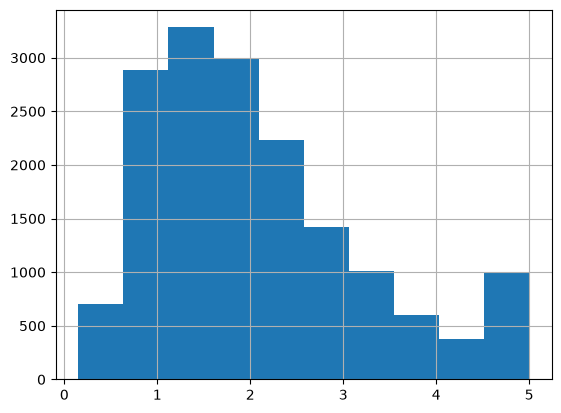

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# 目標值y應該是資料上限為5，不論5, 6, 7, 8, 9, 或是更高都會被歸類在5
y_train.hist()

In [ ]:
# 變數全部都是連續型變數
X_train.info()

<class 'pandas.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
dtypes: float64(8)
memory usage: 1.1 MB


In [8]:
# 變數的尺度差異極大，在梯度下降的時候會被數值尺度影響，下降的方向會被尺度較大的那一個變數的方向給引導，導致收線的步數變多或是時間變長
# AveRooms 的最大值有141.9間，AveBedrms有25.6間，不能說不合理，但是這種極端值會把平均直接帶偏，這種樣本可能是outliers，也許該適度過濾，但需要detect誰是outlier
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.880754,1.904294,0.499900,2.566700,3.545800,4.773175,15.000100
HouseAge,16512.0,28.608285,12.602499,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,16512.0,5.435235,2.387375,0.888889,4.452055,5.235874,6.061037,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,1.006508,1.049286,1.100348,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,789.000000,1167.000000,1726.000000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,2.428799,2.817240,3.280000,1243.333333
Latitude,16512.0,35.643149,2.136665,32.550000,33.930000,34.260000,37.720000,41.950000
Longitude,16512.0,-119.582290,2.005654,-124.350000,-121.810000,-118.510000,-118.010000,-114.310000


In [12]:
# 相關係數矩陣
X_train.assign(label=y_train).corr().sort_values(by="label", ascending=False)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
label,0.690647,0.103706,0.158485,-0.051351,-0.026032,-0.022030,-0.142983,-0.046349,1.000000
MedInc,1.000000,-0.121711,0.336013,-0.072550,0.004122,0.022061,-0.076571,-0.017040,0.690647
AveRooms,0.336013,-0.160892,1.000000,0.836163,-0.073733,-0.004922,0.110695,-0.029339,0.158485
HouseAge,-0.121711,1.000000,-0.160892,-0.087983,-0.292283,0.016245,0.005296,-0.101818,0.103706
AveOccup,0.022061,0.016245,-0.004922,-0.006035,0.072330,1.000000,0.005837,-0.000598,-0.022030
Population,0.004122,-0.292283,-0.073733,-0.071267,1.000000,0.072330,-0.102499,0.094276,-0.026032
Longitude,-0.017040,-0.101818,-0.029339,0.016647,0.094276,-0.000598,-0.924485,1.000000,-0.046349
AveBedrms,-0.072550,-0.087983,0.836163,1.000000,-0.071267,-0.006035,0.073161,0.016647,-0.051351
Latitude,-0.076571,0.005296,0.110695,0.073161,-0.102499,0.005837,1.000000,-0.924485,-0.142983


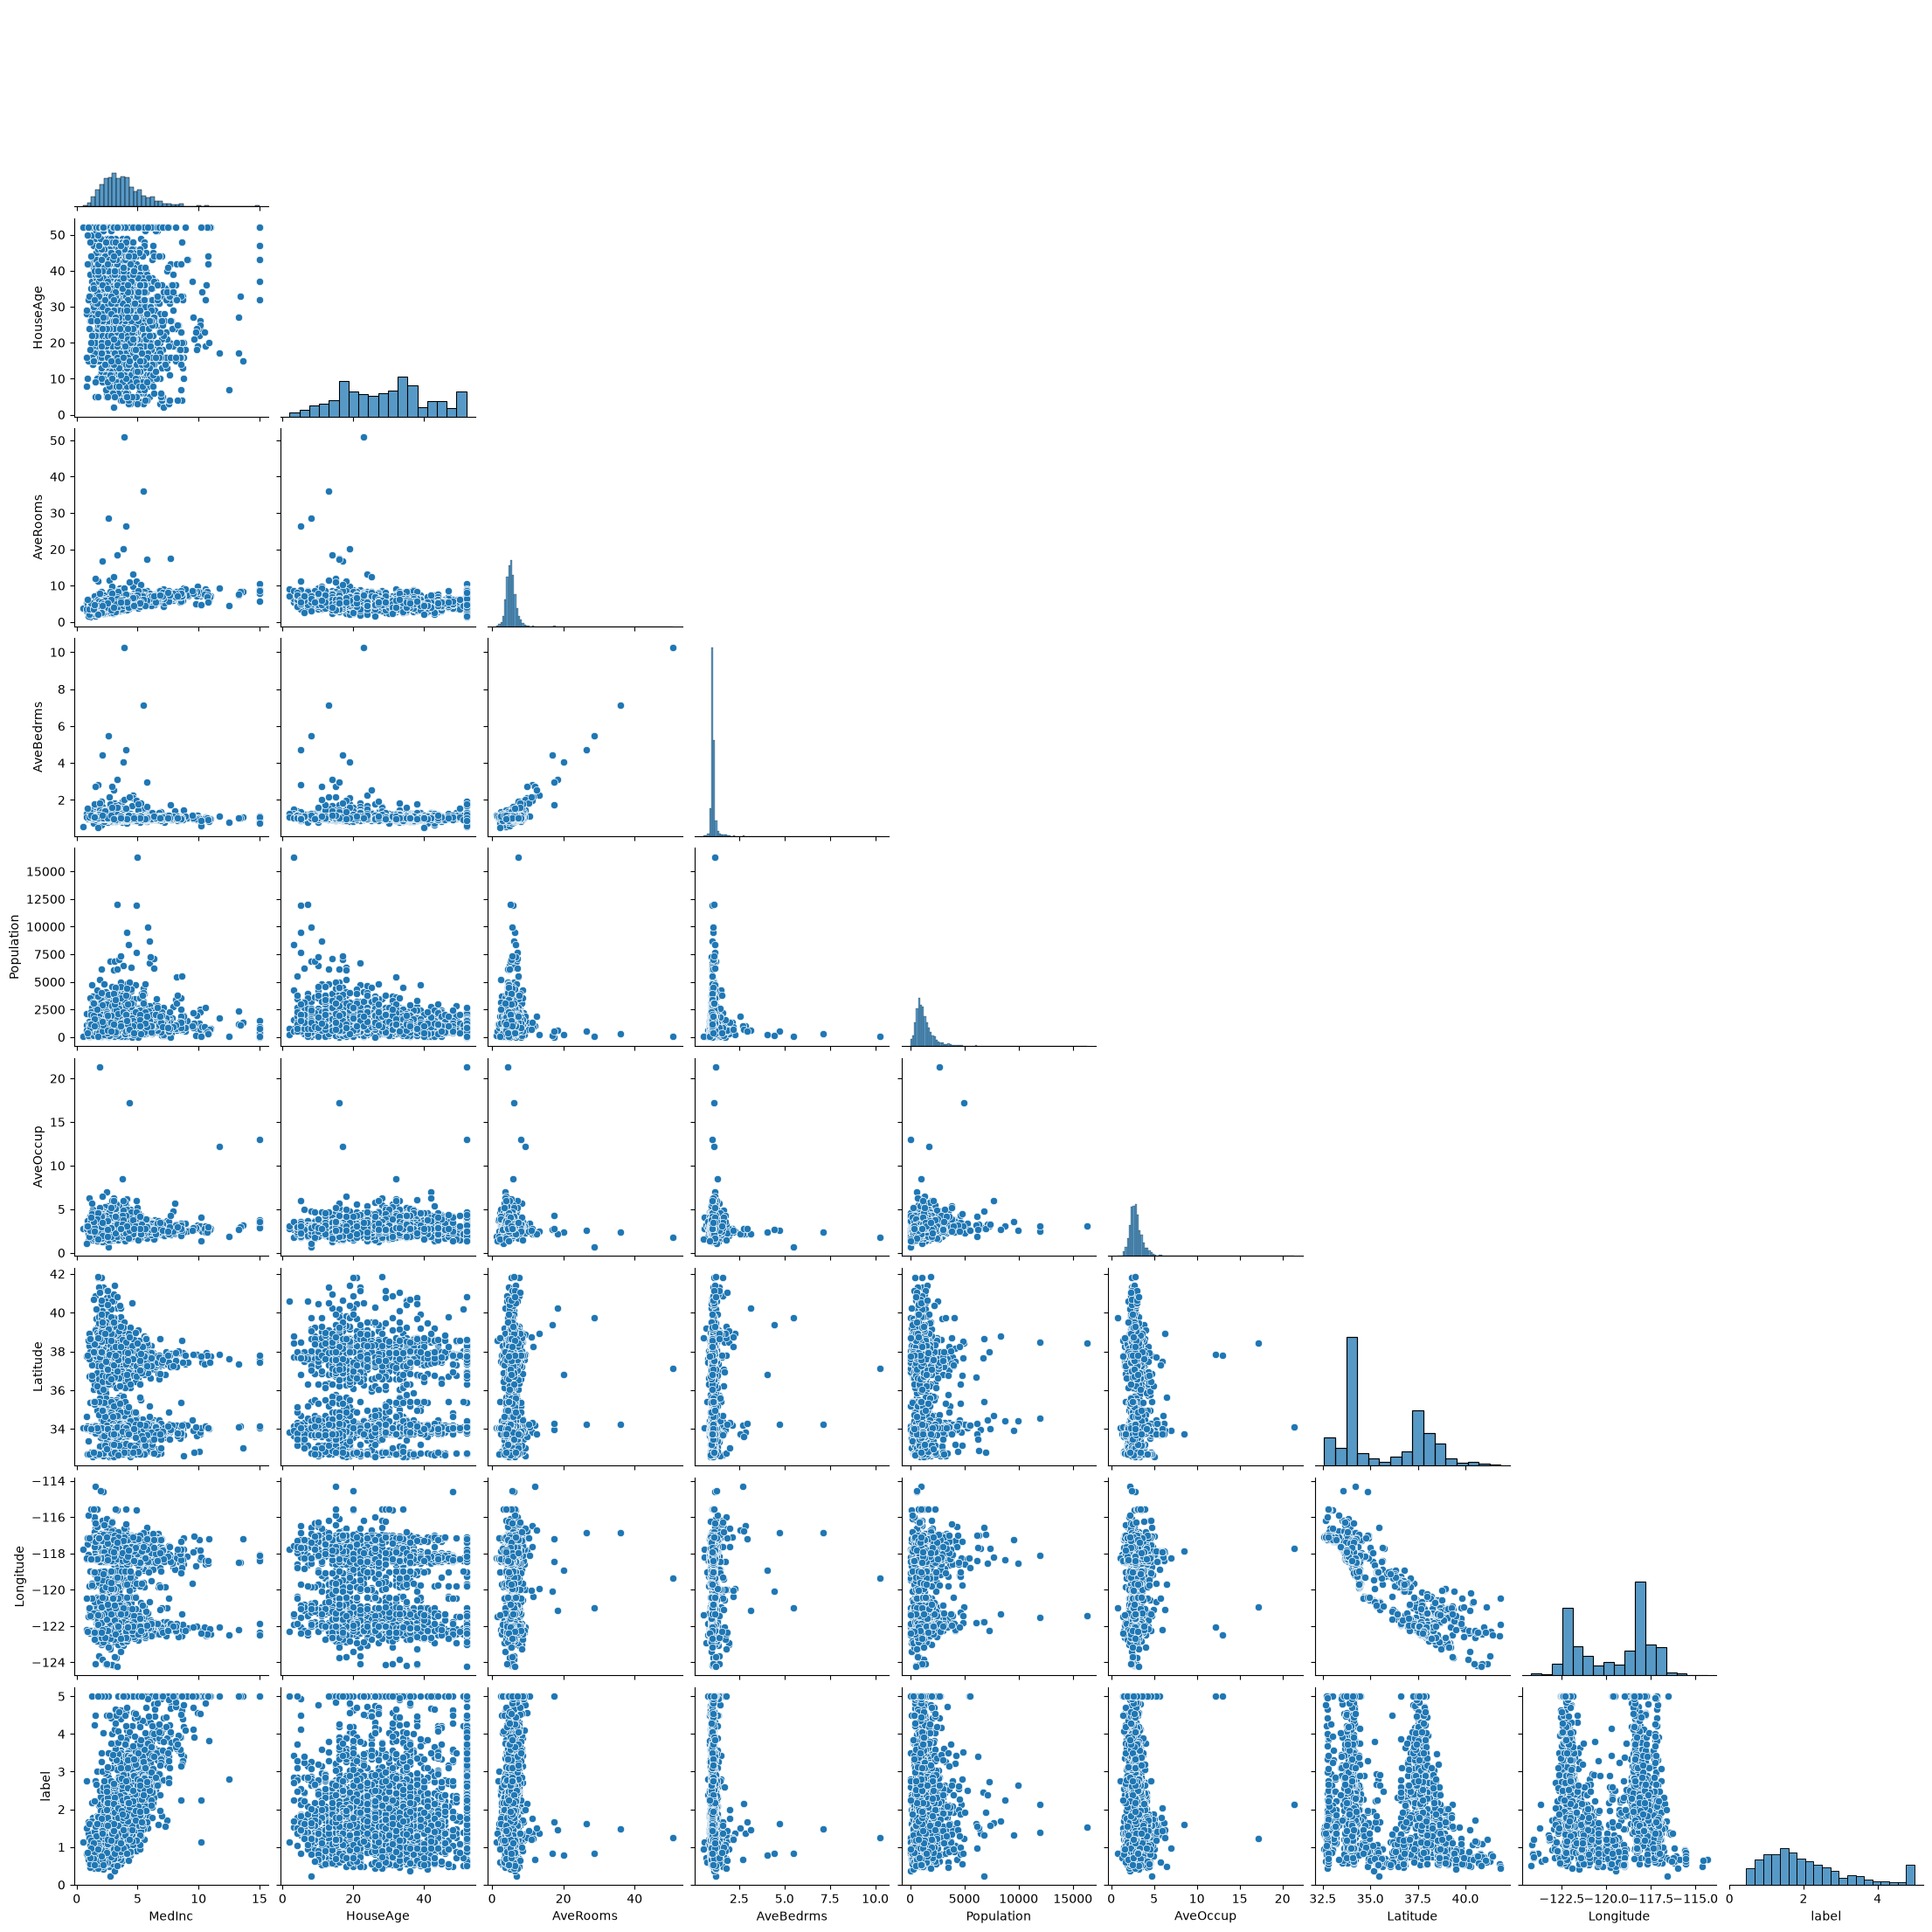

In [22]:
# AveRooms, AveBedrms的相關係數高達 0.836，已經是高度共線性了，實務上這個狀況有可能導致模型難以收斂，對close form會導致係數估計不穩定
# Latitude, Longitude的相關係數也很高，但是是負相關係數
# 對於梯度下降來說會導致收斂變慢
sns.pairplot(X_train.assign(label=y_train).sample(2000), corner=True)

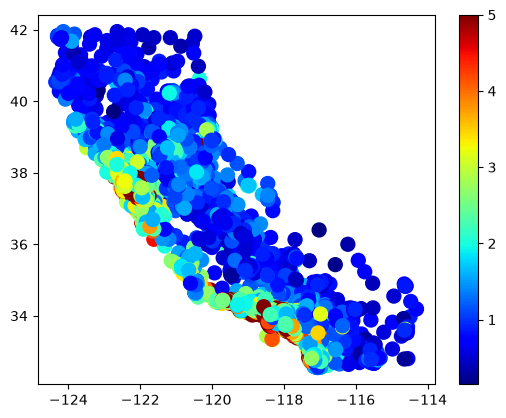

In [ ]:
# 剛好是加州的形狀，可以看出靠海的房子房價越高
# 對於模型來說只會是 w1 * lat + w2 * lon，實際上模型並不知道是否靠海，只知道緯度越低精度越往西房價越高
train = X_train.assign(label=y_train)
scatter = plt.scatter(train["Longitude"], train["Latitude"], c=train["label"], cmap="jet", s=100)
cbar = plt.colorbar(scatter)
plt.show()

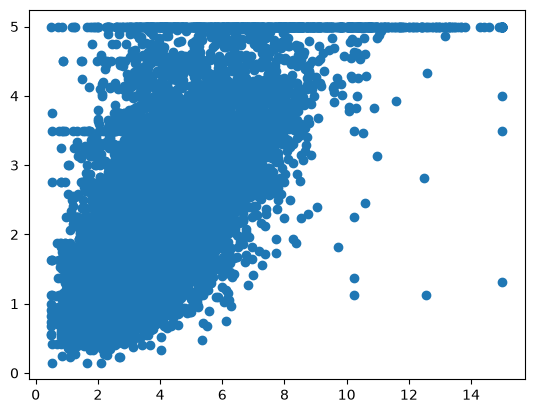

In [24]:
# MedInc 與 label除了 5 有一條線以外，4.5, 3.8附近也看得出可能有一條水平線
plt.scatter(train["MedInc"], train["label"])
plt.show()

---
## 手寫 A：正規方程（Normal Equation）

最小化 ‖Xw − y‖²，對 w 微分令其為 0 → **w = (XᵀX)⁻¹ Xᵀ y**

建議先在紙上推一次再寫。

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from ml_dl_llm.data import load_california_housing
from ml_dl_llm.metrics import regression_metrics

X_train, X_test, y_train, y_test = load_california_housing()
feature_names = X_train.columns.tolist()

# 只用訓練集 fit scaler，再套到測試集（避免資料洩漏）
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


def add_bias(X):
    """在 X 最左邊補一欄 1，讓 bias 變成係數向量的第 0 個元素。"""
    X = np.asarray(X, dtype=float)
    return np.c_[np.ones(len(X)), X]


class LinearRegressionNE:
    """用正規方程一步求解。"""

    def fit(self, X, y):
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 1：解 (Xbᵀ Xb) θ = Xbᵀ y 得到 θ（長度 = 特徵數 + 1）
        #   - 用 np.linalg.solve(A, b)，不要用 np.linalg.inv（想想為什麼）
        #   - θ[0] 是 bias，θ[1:] 是各特徵權重
        theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
        self.b_ = theta[0]
        self.w_ = theta[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

In [ ]:
# 實驗：raw vs 標準化
ne_raw = LinearRegressionNE().fit(X_train, y_train)
ne_s = LinearRegressionNE().fit(X_train_s, y_train)

print("raw    train:", regression_metrics(y_train, ne_raw.predict(X_train)))
print("scaled train:", regression_metrics(y_train, ne_s.predict(X_train_s)))
print("兩者預測值最大差異：", np.abs(ne_raw.predict(X_train) - ne_s.predict(X_train_s)).max())

coef = pd.DataFrame({"raw": ne_raw.w_, "scaled": ne_s.w_}, index=feature_names)
coef.loc["(bias)"] = [ne_raw.b_, ne_s.b_]
display(coef.round(4))

Xb_raw, Xb_s = add_bias(X_train), add_bias(X_train_s)
print(f"XᵀX 條件數 raw   ：{np.linalg.cond(Xb_raw.T @ Xb_raw):.3e}")
print(f"XᵀX 條件數 scaled：{np.linalg.cond(Xb_s.T @ Xb_s):.3e}")

# TODO 2（用註解回答）
#   (1) 預測值一樣嗎？係數一樣嗎？為什麼？
#    預測值幾乎一樣，這個寫法基本上只是矩陣的運算而已，理論上數值會一模一樣，現在看到有差異是因為電腦浮點數或是solver的精度導致的，並不是數學上本身有問題。
#    標準化只是對每一欄做 x′ = (x − μ) / σ，也就是縮放加平移。線性模型本身就有 w 和 b 可以調，縮放可以被 w 吸收，平移可以被 b 吸收。所以兩種資料能表達的函數完全一樣，最佳解的預測值也就一樣。
#
#    係數不一樣，係數之間有精確的換算關係：w_scaled = w_raw × σ
#   (2) 條件數差幾個數量級？
#    raw ≈ 5.6e10、scaled ≈ 4.3e1，差約 9 個數量級。
#    條件數 κ = λ_max / λ_min，代表誤差會被放大的倍數（κ ≈ 10^k 約損失 k 位有效數字）。
#    raw 的大 κ 主要來自特徵尺度差異（Population ~1e3 vs AveBedrms ~1），標準化就能修掉；
#    上面預測值差了 1e-9，正是 raw 的大 κ 把浮點誤差（~1e-16）放大的結果。
#    另外 κ(XᵀX) = κ(X)²，正規方程先算 XᵀX 會把病態程度平方，所以 sklearn 改用 lstsq（SVD）。
#   (3) AveRooms、AveBedrms 的係數正負號，跟它們和 y 的相關係數（0.158、-0.051）方向一致嗎？用共線性解釋。
#    兩個都相反：AveRooms 相關 +0.158 但係數 −0.29；AveBedrms 相關 −0.051 但係數 +0.34。
#    相關係數只看單一特徵與 y 的關係；多元回歸係數是「其他特徵固定時」該特徵的效果，兩者回答不同問題。
#    兩者相關 0.84，幾乎同進同退，模型難以分辨功勞歸誰，常出現一正一負互相抵消的解，係數也因此不穩定。
#    （白話：房間總數固定時，臥室比例越高、客廳等公共空間越少 → 這組係數不宜直接解讀為因果）
#    這是共線性的典型症狀，Ridge（加 αI 墊高 λ_min）可以讓這組係數變穩定。


raw    train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
scaled train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
兩者預測值最大差異： 1.1221779061543202e-09


,raw,scaled
MedInc,0.4487,0.8544
HouseAge,0.0097,0.1225
AveRooms,-0.1233,-0.2944
AveBedrms,0.7831,0.3393
Population,-0.0000,-0.0023
AveOccup,-0.0035,-0.0408
Latitude,-0.4198,-0.8969
Longitude,-0.4337,-0.8698
(bias),-37.0233,2.0719


XᵀX 條件數 raw   ：5.642e+10
XᵀX 條件數 scaled：4.283e+01


---
## 手寫 B：梯度下降（Gradient Descent）

Loss 用 MSE = (1/n) Σ (ŷᵢ − yᵢ)²，每個 epoch 用全部資料算一次梯度（full-batch）。
目標：收斂到跟正規方程**同一組**係數。

In [ ]:
class LinearRegressionGD:
    """Full-batch 梯度下降，最小化 MSE。"""

    def __init__(self, lr=0.1, n_epochs=1000, tol=1e-10):
        self.lr = lr
        self.n_epochs = n_epochs
        self.tol = tol  # loss 改善小於 tol 就提早停

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.w_ = np.zeros(d)
        self.b_ = 0.0
        self.loss_history_ = []

        for epoch in range(self.n_epochs):
            # TODO 3：前向計算
            #   y_hat：目前參數下的預測值，shape (n,)
            #   loss ：MSE（純量）
            y_hat = X @ self.w_ + self.b_
            residual = y_hat - y
            loss = (residual ** 2).mean()

            # TODO 4：梯度 —— MSE 分別對 w、b 偏微分
            #   grad_w shape (d,)、grad_b 是純量
            #   提示：先算殘差 r = y_hat - y，再用矩陣運算，不要寫 for 迴圈
            grad_w = (2 / n) * X.T @ residual
            grad_b = (2 / n) * np.sum(residual)

            # TODO 5：參數更新（兩行）
            self.w_ -= self.lr * grad_w
            self.b_ -= self.lr * grad_b

            self.loss_history_.append(loss)
            if not np.isfinite(loss):  # 發散就停
                break
            if epoch > 0 and abs(self.loss_history_[-2] - loss) < self.tol:
                break
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

epochs： 1288   final MSE： 8552.111768668447
w 與正規方程的最大差異： 1.4478633425518694e-06
b 與正規方程的差異    ： 4.440892098500626e-16


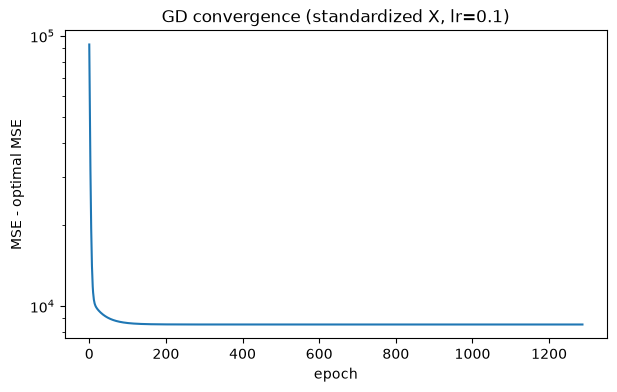

In [36]:
# 在標準化資料上跑，跟正規方程的解比對
gd = LinearRegressionGD(lr=0.1, n_epochs=5000).fit(X_train_s, y_train)
print("epochs：", len(gd.loss_history_), "  final MSE：", gd.loss_history_[-1])
print("w 與正規方程的最大差異：", np.abs(gd.w_ - ne_s.w_).max())
print("b 與正規方程的差異    ：", abs(gd.b_ - ne_s.b_))

best_mse = np.mean((ne_s.predict(X_train_s) - y_train) ** 2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.maximum(np.array(gd.loss_history_) - best_mse, 1e-16))
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE - optimal MSE")
ax.set_title("GD convergence (standardized X, lr=0.1)")
plt.show()

In [40]:
# 實驗：學習率 × 是否標準化
rows = []
with np.errstate(over="ignore", invalid="ignore"):
    for data_name, X in [("scaled", X_train_s), ("raw", X_train)]:
        for lr in [0.5, 0.1, 0.01, 1e-6, 1e-7]:
            m = LinearRegressionGD(lr=lr, n_epochs=2000).fit(X, y_train)
            rows.append({
                "data": data_name,
                "lr": lr,
                "epochs": len(m.loss_history_),
                "final_mse": m.loss_history_[-1],
            })
display(pd.DataFrame(rows))

# TODO 6（用註解回答）
# 記號：MSE 的 Hessian H = (2/n)·XbᵀXb（含 bias 欄），λ_max、λ_min 為其最大、最小特徵值，κ = λ_max / λ_min。
#   實測：raw    λ_max ≈ 6.7e6、λ_min ≈ 1.2e-4、κ ≈ 5.6e10
#         scaled λ_max ≈ 4.05 、λ_min ≈ 0.095 、κ ≈ 43
#
#   (1) raw 資料在哪些 lr 會發散？最大能用的 lr 大概多少？scaled 為什麼 lr=0.5 也會炸？
#       梯度下降在二次 loss 上，沿第 i 個特徵方向的誤差每步乘上 (1 − lr·λ_i)；
#       只要有任一方向 |1 − lr·λ_i| > 1 就會逐步放大而發散，因此穩定條件為 lr < 2 / λ_max。
#       raw：2/λ_max ≈ 3.0e-7 → lr = 0.5、0.1、0.01、1e-6 皆超過上限而發散，只有 1e-7 穩定。
#       scaled：2/λ_max ≈ 0.494 → lr = 0.5 略超過上限，同樣發散；0.1、0.01 都在範圍內。
#       raw 的 λ_max 之所以極大，是因為 Population（數值 ~1e3）這類大尺度特徵讓 XᵀX 在該方向的曲率非常陡。
#
#   (2) raw 用不會發散的 lr 跑 2000 epochs，MSE 跟最佳解（約 0.52）差多少？為什麼這麼慢？
#       raw、lr = 1e-7、2000 epochs 後 MSE ≈ 1.33，最佳解 ≈ 0.518，仍差約 0.8，遠未收斂。
#       lr 被最陡方向限制在 ~1e-7，但在最平緩方向每步收縮因子 1 − lr·λ_min ≈ 1 − 1e-11，幾乎不動。
#       收斂所需步數約 O(κ) ≈ 1e10，2000 步相對而言等於沒有前進。
#       對照 scaled、lr = 0.1：最慢方向收縮因子 ≈ 1 − 0.1·0.095 ≈ 0.99，約 776 步即收斂到 tol。
#
#   (3) 連結到 TODO 2 的條件數：條件數大，對梯度下降代表什麼？
#       κ 決定梯度下降的「收斂速度」：lr 上限由 λ_max 決定（< 2/λ_max），最慢方向的進度由 lr·λ_min 決定，
#       兩者合起來使最慢方向每步收縮因子約為 1 − 2/κ，所需迭代次數約與 κ 成正比。
#       幾何上，κ 大代表 loss 等高線是細長的橢圓（狹長山谷）：梯度主要指向陡峭的谷壁而非谷底方向，
#       於是在谷壁間來回震盪、沿谷底推進極慢。
#       注意：發散的直接原因是 lr > 2/λ_max，而不是 κ 本身；κ 大的後果是「所有不發散的 lr 都慢到不可用」。
#       標準化把 κ 從 5.6e10 降到 43，所以 scaled 版本能用大 lr 並在數百步內收斂。
#       （TODO 2 的「誤差放大」是 κ 在直接解線性方程組時的意義；在梯度下降中 κ 主要反映收斂速度。）


,data,lr,epochs,final_mse
0,scaled,5.000000e-01,2000,2.289048e+40
1,scaled,1.000000e-01,776,5.179331e-01
2,scaled,1.000000e-02,2000,5.183998e-01
3,scaled,1.000000e-06,2000,5.589813e+00
4,scaled,1.000000e-07,2000,5.625735e+00
5,raw,5.000000e-01,25,inf
6,raw,1.000000e-01,28,inf
7,raw,1.000000e-02,33,inf
8,raw,1.000000e-06,203,inf
9,raw,1.000000e-07,2000,1.333204e+00


---
## 手寫 C：Ridge（L2 正則化）

目標函數：‖y − Xw − b‖² + α‖w‖²（bias **不**懲罰，跟 sklearn 的定義相同）

閉式解：θ = (XbᵀXb + αI′)⁻¹ Xbᵀy，其中 I′ 是單位矩陣但 bias 那格為 0。

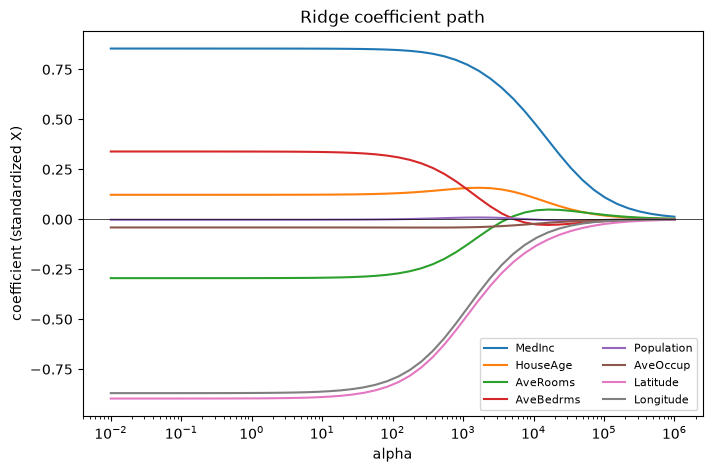

In [ ]:
class RidgeNE(LinearRegressionNE):
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 7：Ridge 閉式解
        #   - 建一個 (d+1)×(d+1) 的單位矩陣，把 [0, 0] 設成 0（bias 不懲罰）
        #   - 一樣用 np.linalg.solve
        identity_matrix = np.identity(n=Xb.shape[1])
        identity_matrix[0, 0] = 0
        theta = np.linalg.solve(Xb.T @ Xb + self.alpha * identity_matrix, Xb.T @ y)
        self.b_, self.w_ = theta[0], theta[1:]
        return self


# 係數路徑：alpha 由小到大，看每個係數怎麼被壓向 0
alphas = np.logspace(-2, 6, 50)
paths = np.array([RidgeNE(a).fit(X_train_s, y_train).w_ for a in alphas])

fig, ax = plt.subplots(figsize=(8, 5))
for j, name in enumerate(feature_names):
    ax.plot(alphas, paths[:, j], label=name)
ax.set_xscale("log")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("alpha")
ax.set_ylabel("coefficient (standardized X)")
ax.set_title("Ridge coefficient path")
ax.legend(fontsize=8, ncol=2)
plt.show()

# TODO 8（用註解回答）
#   (1) AveRooms／AveBedrms、Latitude／Longitude 這兩組共線的係數，隨 alpha 變大怎麼變化？
#       整體：α → ∞ 時所有係數單調或近單調地收縮至 0；α ≲ 10² 時係數幾乎等於 OLS 解（懲罰相對 XᵀX 可忽略）。
#       AveRooms／AveBedrms：OLS 下為一負一正（−0.29、+0.34）互相抵消；α 增大後 AveBedrms 降向 0，
#         AveRooms 在 α ≈ 3×10³ 附近由負轉正，之後以小正值趨近 0 —— 符號回到與其相關係數（+0.158）相同的方向。
#       原因：Ridge 解 w = (XᵀX + αI)⁻¹Xᵀy，當 α 遠大於 XᵀX 的特徵值時 w ≈ Xᵀy / α；
#         在標準化資料上 Xᵀy ∝ 各特徵與 y 的相關係數，因此強正則化下係數的「方向」趨近單變量相關，
#         不再區分共線特徵間的條件效果，OLS 中「一正一負互相抵消」的解被拆除。
#       Latitude／Longitude：兩者與 y 的相關皆為負，故不翻號；兩條路徑幾乎重合、同步收縮 ——
#         Ridge 對高度相關的特徵傾向把權重「平均分攤」，而非給出一大一小或一正一負的極端組合。
#       （補充）HouseAge 在 α ≈ 10³ 附近先微幅上升再下降：其他特徵被壓縮後，它暫時承接了部分解釋力，
#         顯示 Ridge 路徑不一定對每個係數都單調。
#   (2) 為什麼 Ridge 一定要在標準化後的資料上做？（想想 α‖w‖² 對不同尺度的特徵公平嗎）
#       懲罰項 α‖w‖² = α Σ w_j² 對每個係數施加相同的懲罰，但係數大小取決於特徵的單位：
#         若特徵 x_j 放大 c 倍，等價模型的係數縮小為 w_j / c，懲罰則變為原本的 1/c²。
#       因此在 raw 資料上，數值大的特徵（如 Population ~1e3）係數本來就極小，幾乎不受懲罰；
#         數值小的特徵係數較大，被不成比例地重罰。收縮程度取決於任意的單位選擇（美元 vs 萬美元），而非特徵的重要性。
#       Ridge 解不具尺度不變性（scale equivariance），OLS 則有；標準化使各特徵 std = 1，懲罰才在特徵間公平。
#       （注意：這與收斂無關 —— Ridge 有閉式解，且 +αI 會提高 λ_min、降低條件數，數值上反而更穩定。）
#       實務：標準化也要只在訓練集 fit，用 Pipeline(StandardScaler(), Ridge()) 可避免資料洩漏。


---
## sklearn：LinearRegression、Ridge、Lasso、ElasticNet

In [ ]:
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

sk_models = {
    "LinearRegression (sklearn)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge a=1 (sklearn)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso a=0.01 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "Lasso a=0.1 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "ElasticNet a=0.01 (sklearn)": make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5)),
}
for m in sk_models.values():
    m.fit(X_train, y_train)  # pipeline 吃原始資料

ridge_s = RidgeNE(1.0).fit(X_train_s, y_train)
coef = pd.DataFrame({name: m[-1].coef_ for name, m in sk_models.items()}, index=feature_names)
coef["scratch NE"] = ne_s.w_
coef["scratch Ridge a=1"] = ridge_s.w_
display(coef.round(4))

# 驗證：手寫和 sklearn 應該幾乎一模一樣（差異 ~1e-10 等級）
print("NE    vs sklearn：", np.abs(sk_models["LinearRegression (sklearn)"][-1].coef_ - ne_s.w_).max())
print("Ridge vs sklearn：", np.abs(sk_models["Ridge a=1 (sklearn)"][-1].coef_ - ridge_s.w_).max())

# TODO 9
#   (1) 把 Lasso 的 alpha 改成 0.1 再跑一次，哪些係數被壓成剛好 0？Ridge 會這樣嗎？
#       Lasso α = 0.1：AveRooms、AveBedrms、Population、AveOccup、Longitude 恰為 0，僅保留 MedInc、HouseAge、Latitude（≈ −0.01）。
#       Lasso α = 0.01：只有 Population 為 0，其餘係數較 OLS 小幅收縮。
#       Ridge 不會產生恰為 0 的係數，只會連續收縮、在 α → ∞ 時漸近 0。
#       原因：L1 懲罰 α|w_j| 在 w_j = 0 不可微，最佳條件為 |x_jᵀ(y − Xw)| ≤ nα 時 w_j = 0（soft-thresholding），
#         只要某特徵對殘差的解釋力不足以抵過懲罰，係數就被精確設為 0 → 稀疏解、兼具特徵選擇。
#         L2 懲罰可微，梯度 2αw_j 在 w_j → 0 時跟著趨近 0，懲罰的「推力」消失，因此只縮小不歸零。
#         幾何上：L1 約束區域是菱形（尖角落在座標軸上），MSE 等高線易在尖角相切；L2 是圓，無尖角。
#       共線特徵的處理差異：Lasso 對 Latitude／Longitude 只保留一個、另一個歸零，且選誰不穩定；
#         Ridge 則讓兩者係數相近並同步收縮（平均分攤）；ElasticNet（L1 + L2）介於兩者之間，
#         能稀疏化又傾向成組保留相關特徵。
#       另注意：α = 0.1 幾乎砍掉經緯度，但 EDA 顯示地理位置對房價很重要 → 預期測試集表現明顯變差（過度正則化／欠擬合）。
#   (2) Lasso a=0.01 和 Ridge a=1 的懲罰力道可以直接比嗎？
#       不能直接比較，原因有二：
#       ① 目標函數的尺度不同：
#            Ridge（sklearn）：‖y − Xw‖² + α‖w‖₂²
#            Lasso（sklearn）：(1/2n)‖y − Xw‖² + α‖w‖₁
#          Lasso 的資料項除以 2n，等價於未正規化形式 ‖y − Xw‖² + 2nα‖w‖₁；
#          本例 n = 16512，α = 0.01 對應 2nα ≈ 330，與 Ridge 的 α = 1 不在同一量級，
#          這也是 Lasso α = 0.01 的收縮明顯大於 Ridge α = 1 的原因。
#       ② 懲罰的函數形式不同：‖w‖₁ 與 ‖w‖₂² 對係數大小的反應不同（線性 vs 平方），即使尺度對齊也無法一對一換算。
#       1/(2n) 的作用：1/n 使 α 的意義不隨樣本數改變（資料量加倍時同一 α 效果不變）；1/2 用來抵消平方項微分產生的 2。
#       （sklearn 的 Ridge 未除以 n 屬於歷史慣例上的不一致，並非刻意設計。）
#       實務上 α 不靠手動比較，而是用交叉驗證選擇（RidgeCV、LassoCV）。


,LinearRegression (sklearn),Ridge a=1 (sklearn),Lasso a=0.01 (sklearn),Lasso a=0.1 (sklearn),ElasticNet a=0.01 (sklearn),scratch NE,scratch Ridge a=1
MedInc,0.8544,0.8543,0.8010,0.7106,0.8240,0.8544,0.8543
HouseAge,0.1225,0.1226,0.1271,0.1065,0.1300,0.1225,0.1226
AveRooms,-0.2944,-0.2942,-0.1628,-0.0000,-0.2161,-0.2944,-0.2942
AveBedrms,0.3393,0.3390,0.2062,0.0000,0.2563,0.3393,0.3390
Population,-0.0023,-0.0023,-0.0000,-0.0000,-0.0000,-0.0023,-0.0023
AveOccup,-0.0408,-0.0408,-0.0306,-0.0000,-0.0359,-0.0408,-0.0408
Latitude,-0.8969,-0.8962,-0.7901,-0.0115,-0.7884,-0.8969,-0.8962
Longitude,-0.8698,-0.8691,-0.7557,-0.0000,-0.7570,-0.8698,-0.8691


NE    vs sklearn： 3.430589146091734e-14
Ridge vs sklearn： 3.164135620181696e-14


---
## 用測試集評估成績

,mae,rmse,r2,mape
LinReg normal-eq (scratch),0.5332,0.7456,0.5758,31.9522
LinReg GD (scratch),0.5332,0.7456,0.5758,31.9518
Ridge a=1 (scratch),0.5332,0.7456,0.5758,31.9512
LinearRegression (sklearn),0.5332,0.7456,0.5758,31.9522
Ridge a=1 (sklearn),0.5332,0.7456,0.5758,31.9512
Lasso a=0.01 (sklearn),0.5353,0.7404,0.5816,32.0066
Lasso a=0.1 (sklearn),0.6222,0.8244,0.4814,39.9724
ElasticNet a=0.01 (sklearn),0.5341,0.7416,0.5803,31.9413


,model,rmse,time,mae,r2,mape,params,notes
0,Lasso a=0.01 (sklearn),0.7404,2026-10-23 19:35,0.5353,0.5816,32.0066,NaN,NaN
1,ElasticNet a=0.01 (sklearn),0.7416,2026-10-23 19:35,0.5341,0.5803,31.9413,NaN,NaN
2,LinReg normal-eq (scratch),0.7456,2026-10-23 19:35,0.5332,0.5758,31.9522,"{""scaled"": true}",NaN
3,LinReg GD (scratch),0.7456,2026-10-23 19:35,0.5332,0.5758,31.9518,"{""lr"": 0.1, ""epochs"": 776}",NaN
4,Ridge a=1 (scratch),0.7456,2026-10-23 19:35,0.5332,0.5758,31.9512,"{""alpha"": 1.0}",NaN
5,LinearRegression (sklearn),0.7456,2026-10-23 19:35,0.5332,0.5758,31.9522,NaN,NaN
6,Ridge a=1 (sklearn),0.7456,2026-10-23 19:35,0.5332,0.5758,31.9512,NaN,NaN
7,Lasso a=0.1 (sklearn),0.8244,2026-10-23 19:35,0.6222,0.4814,39.9724,NaN,NaN


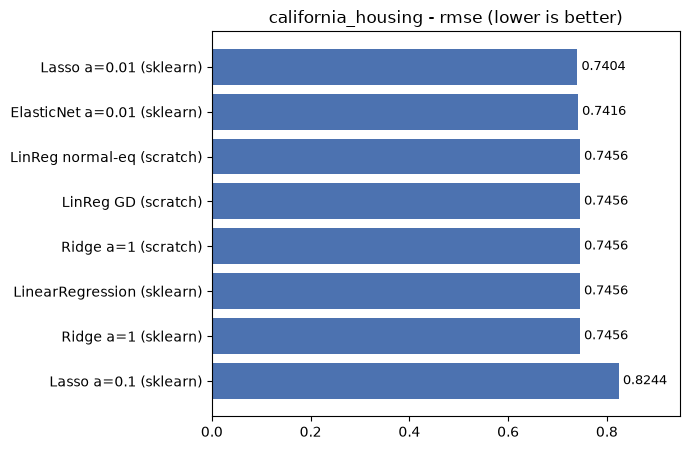

In [47]:
from ml_dl_llm.results import compare, log_result

BENCH = "california_housing"

# 名稱: (模型, 對應的測試資料, 要記下的參數)
eval_models = {
    "LinReg normal-eq (scratch)": (ne_s, X_test_s, {"scaled": True}),
    "LinReg GD (scratch)": (gd, X_test_s, {"lr": gd.lr, "epochs": len(gd.loss_history_)}),
    "Ridge a=1 (scratch)": (ridge_s, X_test_s, {"alpha": ridge_s.alpha}),
}
for name, m in sk_models.items():
    eval_models[name] = (m, X_test, {})  # sklearn pipeline 吃原始資料

test_scores = {}
for name, (m, X, params) in eval_models.items():
    metrics = regression_metrics(y_test, m.predict(X))
    test_scores[name] = metrics
    log_result(BENCH, name, metrics, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "rmse", higher_is_better=False)

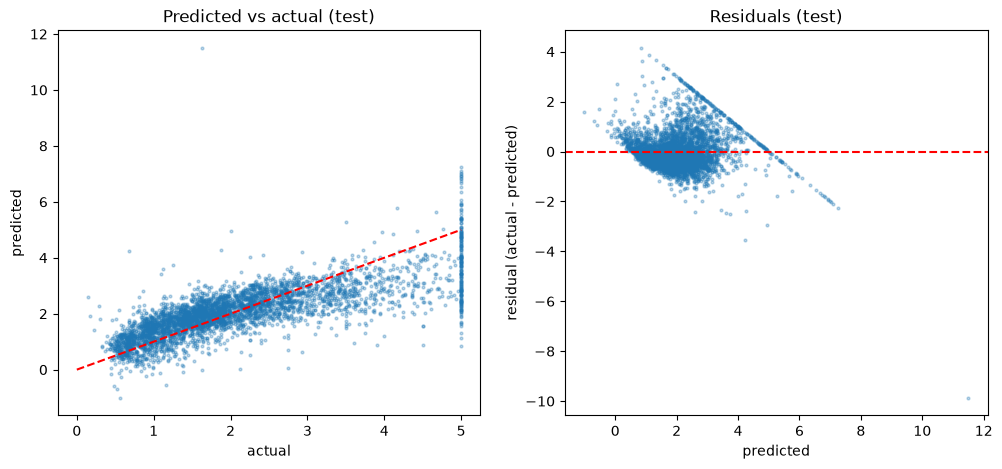

預測出負房價的筆數： 15


In [ ]:
# 診斷圖：預測 vs 實際、殘差
y_pred = ne_s.predict(X_test_s)
resid = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_pred, s=4, alpha=0.3)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_xlabel("actual")
axes[0].set_ylabel("predicted")
axes[0].set_title("Predicted vs actual (test)")

axes[1].scatter(y_pred, resid, s=4, alpha=0.3)
axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("predicted")
axes[1].set_ylabel("residual (actual - predicted)")
axes[1].set_title("Residuals (test)")
plt.show()

print("預測出負房價的筆數：", (y_pred < 0).sum())

# TODO 10（用註解回答，這是本章總結）
#   (1) 右邊 actual = 5 那一排發生什麼事？跟 EDA 的截斷有什麼關係？
#       actual = 5 處形成一條垂直柱：這些樣本真實房價 ≥ 50 萬美元，但標籤被截斷（censored）記為 5.00001。
#       模型對它們的預測分散在約 2～6 之間、多數低於 5 → 系統性低估。
#       問題不在「外推」，而在訓練標籤本身有偏：被壓低的 y 會把回歸斜率往下拉，連帶影響其他高價區的預測。
#       處理方式：移除截斷樣本（簡單但會偏離真實分布）、或用 censored regression（如 Tobit）明確建模上限。
#   (2) 殘差圖有沒有明顯的「結構」（斜線、扇形）？有結構代表模型漏掉了什麼？
#       兩種結構：
#       ① 左上到右下、斜率 −1 的直線：即 (1) 的截斷樣本。actual 固定為 5，殘差 = 5 − ŷ，故對 ŷ 作圖必為斜率 −1 的直線；
#          這是標籤截斷的假象，而非模型漏抓的特徵關係。
#       ② 扇形：ŷ 越大殘差離散程度越大 → 異質變異（heteroscedasticity），違反 OLS「誤差變異為常數」的假設，
#          使係數的標準誤與信賴區間失準（點估計仍不偏）。常見對策是對 y 取 log（或 Box-Cox）以穩定變異，
#          而非加高次項；漏掉非線性項通常表現為殘差對 ŷ 呈彎曲趨勢（如 U 形）。
#       另：測試集出現 15 筆負房價預測，線性模型輸出無正值約束；log(y) 轉換也能一併解決。
#   (3) 這份資料線性模型的 R² 大概卡在多少？你覺得瓶頸是模型還是特徵？
#       合理正則化下的線性模型 test R² ≈ 0.58（RMSE ≈ 0.74，約 7.4 萬美元）；
#       Lasso α = 0.1 的 0.48 是過度正則化（欠擬合）造成，不代表線性模型上限。
#       瓶頸是「線性模型 × 原始特徵」的組合 —— 即 y 與特徵的關係非線性，而線性模型只能表達原始特徵的線性組合：
#         - 經緯度只能形成一個平面（如「越往北越便宜」），無法表達「靠海」或舊金山／洛杉磯等高價聚落；
#         - MedInc 與 y 有飽和、截斷等非線性；Rooms／Occup 等有極端值與長尾。
#       兩條改進路線：
#         ① 保留線性模型、改善特徵：log(y)、log／分箱處理長尾特徵、多項式與交互作用項、經緯度分群或到海岸／城市的距離；
#         ② 改用能自動學習非線性與交互作用的模型：樹模型（Random Forest、GBDT）在此資料 R² 可達 0.8 以上。


---
## 本章小結

### 方法與結果

| 方法 | 求解方式 | 關鍵性質 | test R² |
| --- | --- | --- | --- |
| OLS（正規方程） | 解 (XᵀX)θ = Xᵀy | 一步得解；κ(XᵀX) = κ(X)²，病態時數值不穩 | 0.576 |
| OLS（梯度下降） | θ ← θ − lr·∇MSE | 需 lr < 2/λ_max；收斂步數 ∝ κ → 必須標準化 | 0.576 |
| Ridge（L2） | 解 (XᵀX + αI′)θ = Xᵀy | 墊高 λ_min、穩定共線係數；不產生 0 係數 | 0.576（α=1） |
| Lasso（L1） | 座標下降＋soft-thresholding | 無閉式解；產生稀疏解、兼具特徵選擇 | 0.582（α=0.01）／0.481（α=0.1） |
| ElasticNet | 座標下降 | L1 + L2，稀疏且傾向成組保留相關特徵 | 0.580 |

手寫版本與 sklearn 係數差異約 1e-14，驗證實作正確。

### 核心觀念

1. **最小平方法**：最小化 ‖Xw − y‖²，令梯度為 0 得正規方程；bias 以補一欄 1 併入 θ。
2. **條件數 κ = λ_max / λ_min**
   - 直接解方程組時：誤差放大倍數（κ ≈ 10ᵏ 約損失 k 位有效數字）。
   - 梯度下降時：lr 上限由 λ_max 決定、最慢方向進度由 λ_min 決定 → 收斂步數 ∝ κ。
   - 本資料：raw κ ≈ 5.6e10 → 標準化後 ≈ 43。
3. **標準化**：不改變 OLS 的預測值（係數依 w_scaled = w_raw·σ 換算），但大幅改善條件數；對 Ridge／Lasso 則是必要條件，否則懲罰對不同單位的特徵不公平。
4. **共線性**：使多元回歸係數不穩定、可與單變量相關係數反號（AveRooms／AveBedrms）。
   Ridge 傾向讓共線特徵平均分攤權重；Lasso 傾向只保留其中一個。
5. **L1 vs L2**：L1 在 0 不可微 → 無閉式解、但能把係數壓成恰為 0；L2 可微 → 閉式解、只縮小不歸零。
6. **sklearn 的 α 定義不一致**：Ridge 為 ‖y − Xw‖² + α‖w‖²，Lasso 為 (1/2n)‖y − Xw‖² + α‖w‖₁，兩者 α 不可直接比較；實務用交叉驗證（RidgeCV／LassoCV）選 α。
7. **診斷**：標籤截斷（y = 5）造成系統性低估與殘差圖的斜線；異質變異呈扇形；線性模型會預測出負房價。

### 待補強（之後回來可以學）

**統計推論面（本章偏重預測，未涉及）**
- [ ] OLS 的統計假設（線性、獨立、同質變異、常態誤差）與 Gauss-Markov 定理（BLUE）
- [ ] 係數的標準誤、t 檢定、信賴區間；用 `statsmodels.OLS` 看 summary 表
- [ ] 異質變異的檢定（Breusch-Pagan）與穩健標準誤（HC0–HC3）
- [ ] 多重共線性的量化：VIF（variance inflation factor）
- [ ] 最小平方法 = 高斯誤差下的最大概似估計（MLE）；Ridge／Lasso = 高斯／Laplace 先驗下的 MAP

**數值與最佳化**
- [ ] 用 QR 分解或 SVD（`np.linalg.lstsq`）解最小平方，避免條件數平方；偽逆（pseudo-inverse）
- [ ] 隨機梯度下降（SGD）與 mini-batch：大資料下的做法，以及學習率排程
- [ ] 動量（Momentum）、Adam 如何緩解病態條件數（銜接第二章神經網路）
- [ ] 手寫座標下降 Lasso（soft-thresholding）；LARS 與 Lasso 路徑

**模型與特徵**
- [ ] 用交叉驗證選 α（`RidgeCV`、`LassoCV`、`ElasticNetCV`）並畫驗證曲線
- [ ] 偏差—變異權衡（bias-variance tradeoff）：用 α 或多項式次數觀察欠擬合／過擬合
- [ ] 特徵工程：log(y)（`TransformedTargetRegressor`）、多項式／交互作用項（`PolynomialFeatures`）、經緯度分群或距離特徵，看線性模型 R² 能推到多少
- [ ] 截斷資料的處理：移除 y = 5 樣本的影響、Tobit 回歸
- [ ] 穩健回歸：Huber、RANSAC（對 AveOccup 等極端值較不敏感）
- [ ] 廣義線性模型（GLM）：Poisson、Gamma 回歸，處理正值或計數型目標
